# 6. Local and global space-charge test — Python

1. Edit the inputs and **Restart Kernel and Run All** here.
2. Run all sections of `spacecharge_test.mlx` (readable source: `spacecharge_test.m`).
3. Run `compare_results.ipynb`.

Both methods are tested on the same prescribed beam. Each is compared with **its own original MATLAB expression**, not with the other approximation. This extends test 4 to the full `SpaceChargeState.initialize()` and `update()` paths.

No cavity field, circuit solve, particle tracking or nonlinear convergence is computed. The source/velocity profiles below are controlled test fixtures. All field coefficients are dimensionless, not V/m. Production classes and the original MATLAB solver are unchanged.


In [1]:
# Import necessary libraries and modules

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat
from IPython.display import Markdown, display

from copy import deepcopy
from uuid import uuid4
from scipy.integrate import cumulative_trapezoid


In [2]:
# Import custom modules and classes to be tested

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "6.spacecharge_test"
sys.path.insert(0, str(project_directory / "src"))

from constants import c, etom, mu01
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.beam_state import BeamState

from solver.space_charge import SpaceChargeState


In [3]:
# Set global options for numpy and matplotlib

np.set_printoptions(precision=6, linewidth=140)
# Apply the same dashed gray grid to every subplot.
# "line" places the grid above shaded regions, but below plotted lines.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})

# Display options for Jupyter Notebook Tables

def show_table(rows):
    text = "| Variable | Value | Units | Meaning |\n"
    text += "|---|---|---|---|\n"
    for name, value, units, meaning in rows:
        if isinstance(value, np.ndarray):
            value = np.array2string(value, precision=5, max_line_width=1000)
        elif isinstance(value, (float, np.floating)):
            value = f"{value:.8g}"
        text += f"| `{name}` | {value} | {units} | {meaning} |\n"
    display(Markdown(text))


## 1. Editable inputs

Use `case_name` to choose uniform current, sinusoidal modulation, or a smooth periodically bunched distribution. All three have mean current −16 A and constant entrance energy 180 kV.

Choose `beam_profile`:

- `initial_guess`: the original longitudinally constant initialization.
- `constant_speed`: constant-speed phase advance, with unchanged harmonic amplitudes.
- `synthetic`: a prescribed speed decrease and smooth harmonic-amplitude envelope. This exercises source-position dependence and relativistic factors; it is **not a self-consistent beam solution**.

The default `nn=2` enables space charge. Set `nn=1` to test the original first-iteration bypass, or `factor=0` to disable it. Both SCmethod branches are always evaluated.

`factorregion` sets the source-window extent. `fillfactor` weights upstream prefill in the global result; `DCSPfactor` weights the resulting DC field. As in original MATLAB, either one being zero also disables the **entire prefill calculation** at initialization, including its RF columns.


In [4]:
case_name = "modulated"  # "uniform", "modulated", or "bunched"
beam_profile = "constant_speed"  # "initial_guess", "constant_speed", or "synthetic"
speed_drop = 0.15          # Used only by synthetic: vez decreases from 1 to 0.85.
modulation_growth = 0.30   # Used only by synthetic: smooth amplitude envelope.
nn = 2                    # Snapshot index, not a request to run an outer loop.

Nbeam = 1
rm1, rm2, rc = 0.0, 6.0, 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0 + 0.35
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
if case_name == "uniform":
    weights = np.ones(Nt)
elif case_name == "modulated":
    weights = 1.0 + 0.20*np.cos(t0 + 0.40) + 0.10*np.sin(2*t0 - 0.20)
elif case_name == "bunched":
    weights = np.exp(3.0 * (np.cos(t0 - 0.60) - 1.0))
else:
    raise ValueError("Choose uniform, modulated, or bunched.")
Izt = -16.0 * weights / np.mean(weights)

# Same grid fixture as the previous tests. No cavity fields are calculated.
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{k+1}" for k in range(Nc))

z0, L = -100.0, 3000.0
rcv = np.array([[z0, z0 + L], [1.0, 1.0]])
# Optional taper fixture (tests source-radius indexing, not model validity):
# rcv[1, 1] = 1.2
Nz, Ns = 256, 8
Nlimit, Ntimes = 100, 10
Rlimit, iterfactor = 1.0e-4, 0.5

factor = 1.0
factorregion = 10.0
fillfactor = 1.0
DCSPfactor = 1.0
theta = np.array([0.0, np.pi/2, np.pi, 3*np.pi/2])

assert Nt >= 16 and 1 <= Ns < Nt/2 and nn >= 1
assert 0 <= rm1 < rm2 <= rc
assert factor >= 0 and factorregion >= 0 and fillfactor >= 0 and DCSPfactor >= 0
assert 0 <= speed_drop < 1 and modulation_growth >= 0


## 2. Initialize the complete space-charge state

Initialize the reference, grid and entrance beam first. `SpaceChargeState.initialize()` then computes wp, the fixed prefill, and the five radial-mode factors Eszr; its evolving field arrays start at zero.

The prefill is calculated **before** modifying the in-domain beam below. Its source convention is preserved exactly from MATLAB, not replaced by the test's drifting-profile formula.

Known inherited limitation: enabled prefill with `dN=1` has an ambiguous summation dimension in original MATLAB. This test stops explicitly for that case rather than changing the original expression or accepting a misleading comparison. See test 4 in the README.


In [5]:
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit,
    Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=np.array([0.005, 2.0]),
    upstream_discard_distance_mm=0.0,
    efficiency_end_offset_mm=3.0 * rc,
)

cavities.validate(Nc)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

beam_state = BeamState.initialize(numerical, beam, grid, reference)

assert np.all(grid.rcvs >= beam.rm2)
prefill_enabled = factor != 0 and fillfactor != 0 and DCSPfactor != 0
assert not (prefill_enabled and grid.dN == 1), (
    "Enabled prefill with dN=1 hits the original MATLAB sum-dimension limitation; see test/README.md."
)

space_charge_state = SpaceChargeState.initialize(
    beam, grid, reference, beam_state, factor, fillfactor, DCSPfactor
)
for name in ("Esztotal", "Esz0", "Esz"):
    np.testing.assert_array_equal(
        getattr(space_charge_state, name), np.zeros_like(getattr(space_charge_state, name))
    )
assert space_charge_state.SCmethod == 0
Nfill = len(space_charge_state.zp)


## 3. Prescribed in-domain beam

For constant speed, \(Iz_m(z)=Iz_m(z_0)e^{-im(z-z_0)}\).
For the synthetic fixture, define \(x=(zi-zi_0)/L\),

\[
v_{ez}=1-\mathrm{speed\_drop}\,x,\quad
A=1+\mathrm{modulation\_growth}\sin^2(\pi x),\quad
T(z)=\int_{z_0}^{z}\frac{d\zeta}{v_{ez}(\zeta)}.
\]

Use \(Iz_m=Iz_m(z_0)A e^{-imT}\), \(QQ_m=QQ_m(z_0)A e^{-imT}/v_{ez}\), and \(QQDC=QQDC(z_0)/v_{ez}\). Recompute \(\gamma_z=[1-(s v_{ez})^2]^{-1/2}\).

These formulas deliberately exercise the array inputs. In particular, the amplitude-varying fixture is not asserted to solve continuity or the beam equations.


| Variable | Value | Units | Meaning |
|---|---|---|---|
| `case_name` | modulated | - | Prescribed entrance distribution |
| `beam_profile` | constant_speed | - | Prescribed longitudinal variation |
| `nn` | 2 | iteration | 1 bypasses the evolving-field computation |
| `wp` | 3.7316657e+09 | rad/s | Plasma angular frequency |
| `dN` | 52 | intervals | Source-window half-width |
| `dN*dz` | 40.998686 | mm | Physical half-width and upstream extent |
| `Eszr.shape` | (3806, 5) | - | Grid nodes x five radial modes |
| `Ns` | 8 | harmonics | RF harmonics; DC is stored separately |


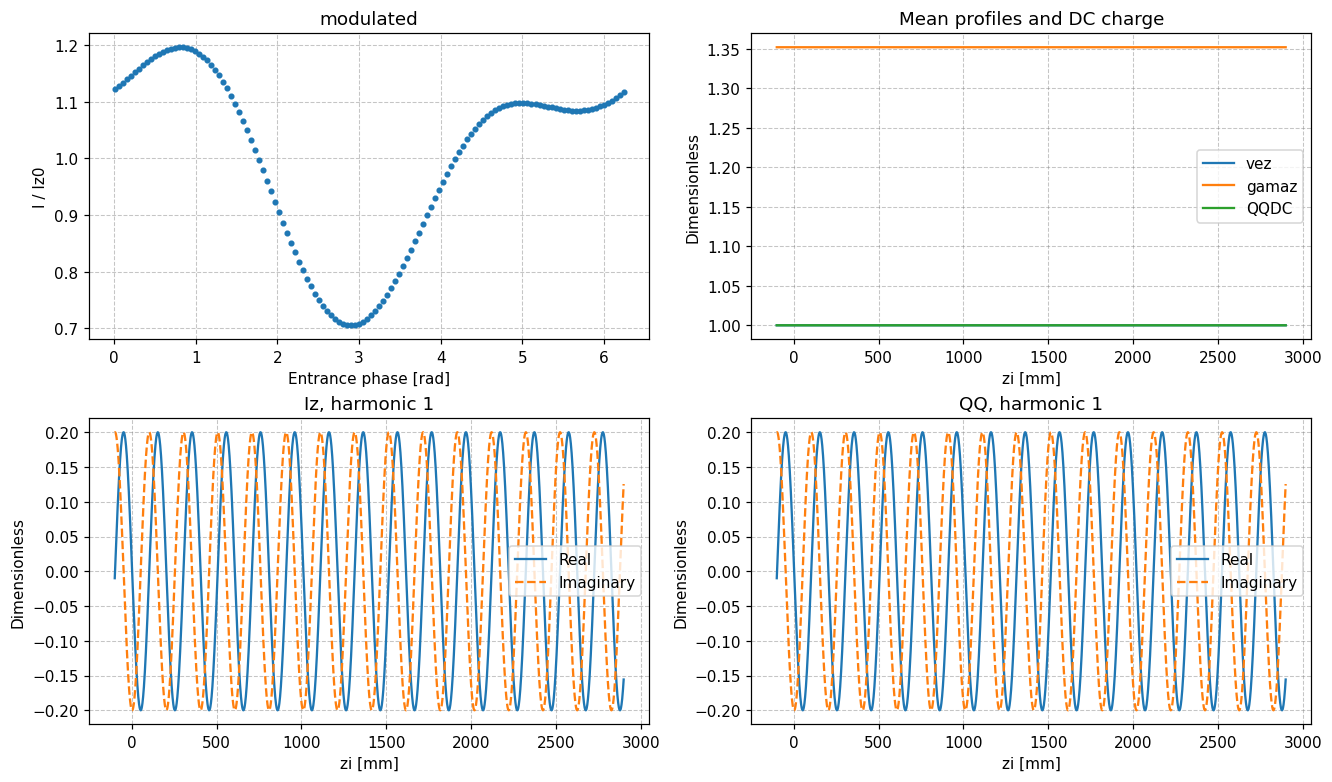

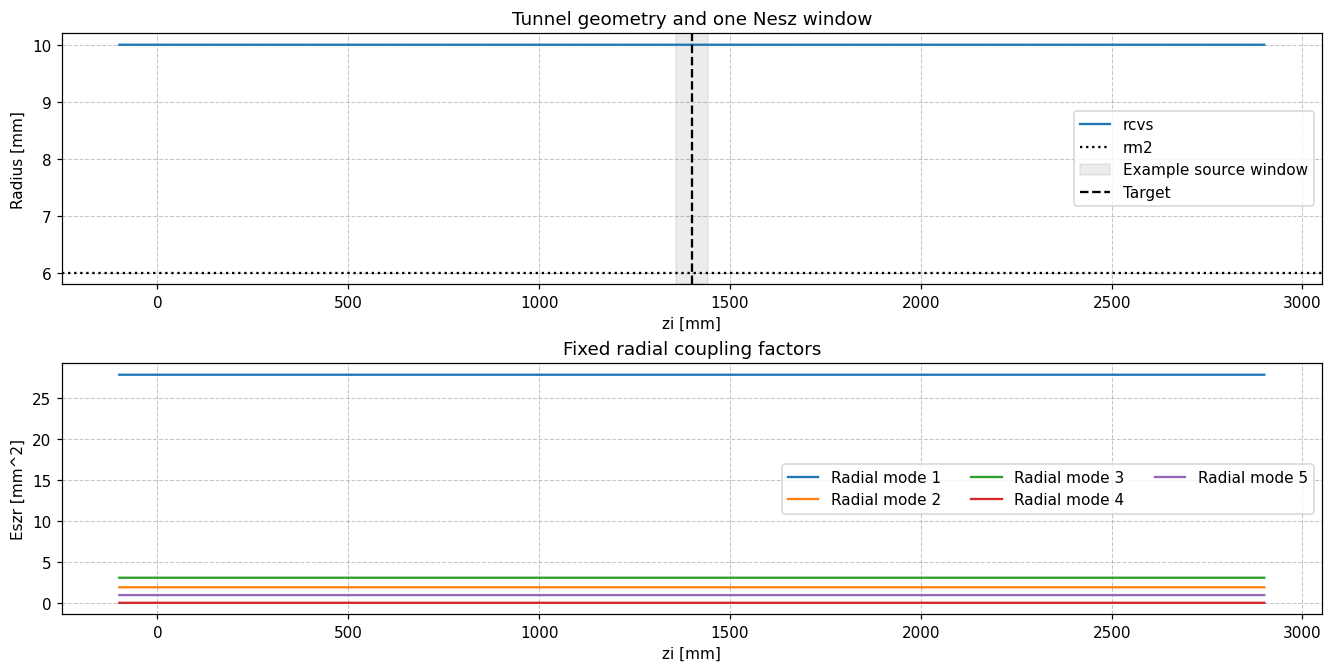

In [6]:
if beam_profile in ("constant_speed", "synthetic"):
    amplitude = np.ones(len(grid.z))
    phase_distance = grid.z - grid.z[0]
    if beam_profile == "synthetic":
        x = (grid.zi - grid.zi[0]) / L
        beam_state.vez[:] = 1.0 - speed_drop * x
        beam_state.gamaz[:] = (1.0 - (reference.s * beam_state.vez)**2)**(-0.5)
        amplitude = 1.0 + modulation_growth * np.sin(np.pi*x)**2
        phase_distance = cumulative_trapezoid(1.0/beam_state.vez, x=grid.z, initial=0.0)
    phase_advance = np.exp(-1.0j * np.outer(phase_distance, np.arange(1, Ns+1)))
    beam_state.Iz[:] *= amplitude[:, None] * phase_advance
    beam_state.QQ[:] *= amplitude[:, None] * phase_advance / beam_state.vez[:, None]
    beam_state.QQDC[:] /= beam_state.vez
elif beam_profile != "initial_guess":
    raise ValueError("Choose initial_guess, constant_speed, or synthetic.")

show_table([
    ("case_name", case_name, "-", "Prescribed entrance distribution"),
    ("beam_profile", beam_profile, "-", "Prescribed longitudinal variation"),
    ("nn", nn, "iteration", "1 bypasses the evolving-field computation"),
    ("wp", space_charge_state.wp, "rad/s", "Plasma angular frequency"),
    ("dN", grid.dN, "intervals", "Source-window half-width"),
    ("dN*dz", grid.dN*grid.dz, "mm", "Physical half-width and upstream extent"),
    ("Eszr.shape", str(space_charge_state.Eszr.shape), "-", "Grid nodes x five radial modes"),
    ("Ns", Ns, "harmonics", "RF harmonics; DC is stored separately"),
])

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
axes[0, 0].plot(np.mod(tn1,2*np.pi), Izt/reference.Iz0, ".")
axes[0, 0].set(xlabel="Entrance phase [rad]", ylabel="I / Iz0", title=case_name)
for name in ("vez", "gamaz", "QQDC"):
    axes[0, 1].plot(grid.zi, getattr(beam_state, name), label=name)
axes[0, 1].set(xlabel="zi [mm]", ylabel="Dimensionless", title="Mean profiles and DC charge")
for ax, name in ((axes[1, 0], "Iz"), (axes[1, 1], "QQ")):
    values = getattr(beam_state, name)[:, 0]
    ax.plot(grid.zi, values.real, label="Real")
    ax.plot(grid.zi, values.imag, "--", label="Imaginary")
    ax.set(xlabel="zi [mm]", ylabel="Dimensionless", title=f"{name}, harmonic 1")
    ax.legend()
axes[0, 1].legend()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained")
axes[0].plot(grid.zi, grid.rcvs, label="rcvs")
axes[0].axhline(beam.rm2, color="black", linestyle=":", label="rm2")
target = len(grid.z)//2
start, stop = grid.Nesz[target]
axes[0].axvspan(grid.zi[start], grid.zi[stop-1], color="gray", alpha=0.15, label="Example source window")
axes[0].axvline(grid.zi[target], color="black", linestyle="--", label="Target")
axes[0].set(xlabel="zi [mm]", ylabel="Radius [mm]", title="Tunnel geometry and one Nesz window")
axes[0].legend()
for p in range(5):
    axes[1].plot(grid.zi, space_charge_state.Eszr[:, p], label=f"Radial mode {p+1}")
axes[1].set(xlabel="zi [mm]", ylabel="Eszr [mm^2]", title="Fixed radial coupling factors")
axes[1].legend(ncol=3)
plt.show()


## 4. Evaluate both methods on the same beam

Call the public `update()` entry point with SCmethod=0 and SCmethod=1 and retain separate copies.

- **Local:** uses Iz, vez and gamaz at each target node; Esz0 and Esztotal remain zero; no prefill is added.
- **Global:** uses QQDC/QQ at source nodes, their gamaz and rcvs, and the five radial modes. The DC kernel uses gamma=1. It integrates only within each Nesz window, then adds the weighted prefill.

The local denominator contains the reference radius rc while its radial factors use rcvs, exactly as original MATLAB. A tapered-radius fixture tests translation fidelity, not the physical validity of applying the local approximation to a taper.


In [7]:
method_results = {}
for label, SCmethod in (("local", 0), ("global", 1)):
    space_charge_state.SCmethod = SCmethod
    # Sentinels verify that update clears previous fields, including bypasses.
    for name in ("Esz", "Esz0", "Esztotal"):
        getattr(space_charge_state, name).fill(1.0 + 2.0j)
    space_charge_state.update(
        nn, beam, grid, reference, beam_state, fillfactor, DCSPfactor
    )
    for name in ("Esz", "Esz0", "Esztotal"):
        method_results[f"{name}_{label}"] = getattr(space_charge_state, name).copy()

Esz_local = method_results["Esz_local"]
Esz0_local = method_results["Esz0_local"]
Esztotal_local = method_results["Esztotal_local"]
Esz_global = method_results["Esz_global"]
Esz0_global = method_results["Esz0_global"]
Esztotal_global = method_results["Esztotal_global"]

phase = np.exp(1.0j * np.outer(np.arange(1, Ns+1), theta))
E_local = Esz0_local.real[:, None] + np.imag(Esz_local @ phase)
E_global = Esz0_global.real[:, None] + np.imag(Esz_global @ phase)


## 5. Local versus global: diagnostic plots, not an equality test

DC is harmonic zero. The global DC field can be nonzero near boundaries or where charge varies, even for a beam with no RF modulation. The local approximation omits this term.

For RF, finite source windows, boundaries, upstream assumptions and varying beam parameters can produce differences. In particular, the prefill source phase convention is inherited unchanged; agreement of the two approximations at the entrance is not assumed.

Every complex coefficient is compared with MATLAB later; these plots simply help explain the two methods.


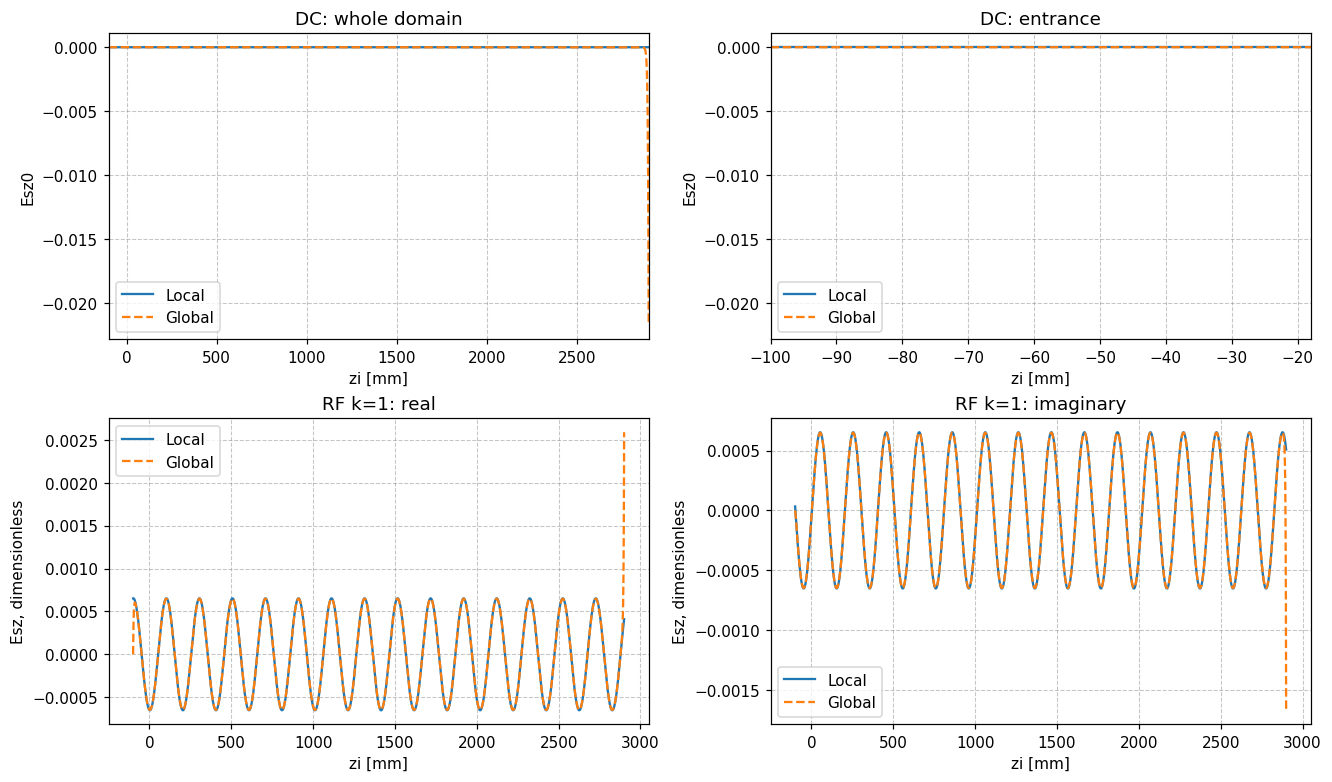

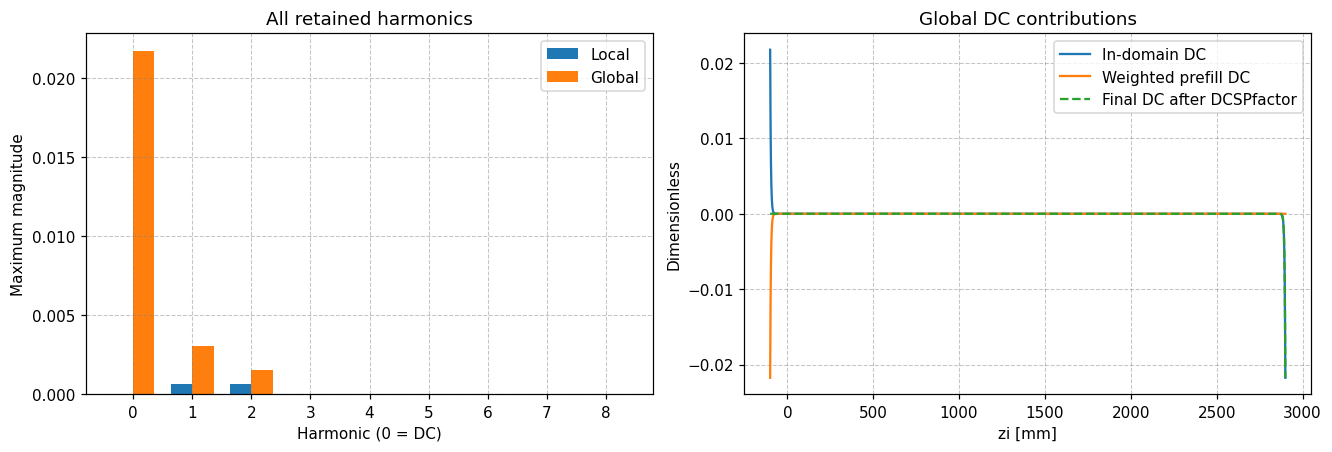

In [8]:
harmonics = np.arange(Ns+1)
local_all = np.column_stack((Esz0_local, Esz_local))
global_all = np.column_stack((Esz0_global, Esz_global))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, limit, title in (
    (axes[0, 0], (grid.zi[0], grid.zi[-1]), "DC: whole domain"),
    (axes[0, 1], (grid.zi[0], min(grid.zi[-1],grid.zi[0]+max(4*rc,2*grid.dN*grid.dz))), "DC: entrance"),
):
    ax.plot(grid.zi, Esz0_local.real, label="Local")
    ax.plot(grid.zi, Esz0_global.real, "--", label="Global")
    ax.set(xlim=limit, title=title, xlabel="zi [mm]", ylabel="Esz0")
    ax.legend()
for ax, part, title in ((axes[1, 0], np.real, "RF k=1: real"), (axes[1, 1], np.imag, "RF k=1: imaginary")):
    ax.plot(grid.zi, part(Esz_local[:, 0]), label="Local")
    ax.plot(grid.zi, part(Esz_global[:, 0]), "--", label="Global")
    ax.set(title=title, xlabel="zi [mm]", ylabel="Esz, dimensionless")
    ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].bar(harmonics-0.18, np.max(np.abs(local_all),axis=0), width=0.36, label="Local")
axes[0].bar(harmonics+0.18, np.max(np.abs(global_all),axis=0), width=0.36, label="Global")
axes[0].set(xticks=harmonics, xlabel="Harmonic (0 = DC)", ylabel="Maximum magnitude", title="All retained harmonics")
axes[0].legend()
axes[1].plot(grid.zi, Esztotal_global[:, 0].real, label="In-domain DC")
axes[1].plot(grid.zi, fillfactor*space_charge_state.Esz00[:, 0].real, label="Weighted prefill DC")
axes[1].plot(grid.zi, Esz0_global.real, "--", label="Final DC after DCSPfactor")
axes[1].set(xlabel="zi [mm]", ylabel="Dimensionless", title="Global DC contributions")
axes[1].legend()
plt.show()


## 6. Reconstructed instantaneous space-charge field

Use the MATLAB convention E(theta)=real(Esz0)+imag(sum(Esz_k*exp(i*k*theta))).
These snapshots are dimensionless space-charge fields only; they contain no cavity RF field. The plots include all retained harmonics.


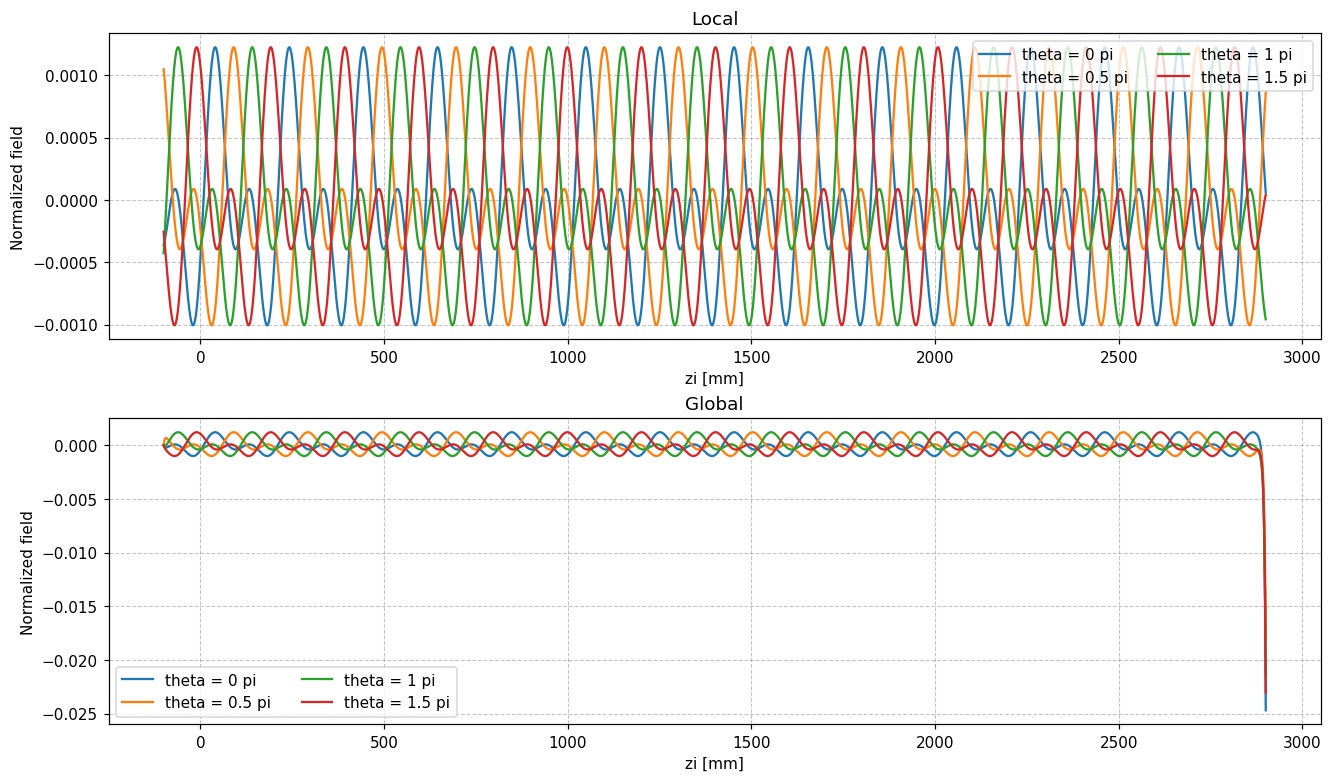

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
for ax, values, title in ((axes[0], E_local, "Local"), (axes[1], E_global, "Global")):
    for j, phase_value in enumerate(theta):
        ax.plot(grid.zi, values[:,j], label=f"theta = {phase_value/np.pi:g} pi")
    ax.set(xlabel="zi [mm]", ylabel="Normalized field", title=title)
    ax.legend(ncol=2)
plt.show()


## 7. Internal consistency and reset checks

Check dimensions, finite complex values, DC reality, the global prefill combination, and the local branch's zero DC/Esztotal arrays. Independently exercise both methods' nn=1 and wp=0 bypasses after seeding nonzero old fields.

These checks do not require local and global RF fields to agree and do not replace the separate MATLAB comparison.


In [10]:
for label in ("local", "global"):
    for name, shape in (
        ("Esz", (len(grid.z), Ns)), ("Esz0", (len(grid.z),)),
        ("Esztotal", (len(grid.z), Ns+1)),
    ):
        values = method_results[f"{name}_{label}"]
        assert values.shape == shape and np.all(np.isfinite(values))
    np.testing.assert_allclose(method_results[f"Esz0_{label}"].imag, 0.0, atol=1e-12)
np.testing.assert_array_equal(Esz0_local, np.zeros_like(Esz0_local))
np.testing.assert_array_equal(Esztotal_local, np.zeros_like(Esztotal_local))
assert space_charge_state.Eszr.shape == (len(grid.z), 5)
assert np.all(np.isfinite(space_charge_state.Eszr)) and np.all(space_charge_state.Eszr >= 0)

if nn == 1 or factor == 0:
    for values in method_results.values():
        np.testing.assert_array_equal(values, np.zeros_like(values))
else:
    np.testing.assert_allclose(
        Esz_global, Esztotal_global[:,1:] + fillfactor*space_charge_state.Esz00[:,1:],
        rtol=1e-10, atol=1e-12,
    )
    np.testing.assert_allclose(
        Esz0_global, DCSPfactor*(Esztotal_global[:,0] + fillfactor*space_charge_state.Esz00[:,0]),
        rtol=1e-10, atol=1e-12,
    )
np.testing.assert_allclose(space_charge_state.Esz00[:,0].imag, 0.0, atol=1e-12)

for SCmethod in (0, 1):
    for disabled in ("first_iteration", "zero_plasma_frequency"):
        probe = deepcopy(space_charge_state)
        probe.SCmethod = SCmethod
        if disabled == "zero_plasma_frequency":
            probe.wp = 0.0
        for name in ("Esz", "Esz0", "Esztotal"):
            getattr(probe, name).fill(1.0+2.0j)
        probe.update(
            1 if disabled == "first_iteration" else 2,
            beam, grid, reference, beam_state, fillfactor, DCSPfactor,
        )
        for name in ("Esz", "Esz0", "Esztotal"):
            np.testing.assert_array_equal(getattr(probe, name), np.zeros_like(getattr(probe, name)))

print("PASS: both Python methods, prefill combination, dimensions and disabled/reset checks.")
print("The Python-MATLAB comparison is a separate step.")


PASS: both Python methods, prefill combination, dimensions and disabled/reset checks.
The Python-MATLAB comparison is a separate step.


## 8. Export raw inputs and Python results

Overwrite only this folder's inputs.mat and python_results.mat. MATLAB independently reconstructs the grid, entrance harmonics, prefill and prescribed in-domain profile. The files contain no Python-derived starting solution for MATLAB.

Y0 is exported one-based; Nesz in Python results retains native zero-based/exclusive-stop indexing. Only its first column needs +1 when comparing with MATLAB. Matrices keep their dimensions, including empty upstream arrays.

A new run_id pairs this export with the subsequent MATLAB run. Rerun both producers after changing inputs. A matching ID is not a checksum against later manual edits.


In [11]:
run_id = uuid4().hex
inputs = {
    **vars(beam), **vars(cavities), **vars(tube), **vars(numerical),
    "factor": factor, "factorregion": factorregion,
    "fillfactor": fillfactor, "DCSPfactor": DCSPfactor, "nn": nn,
    "case_name": case_name, "beam_profile": beam_profile,
    "speed_drop": speed_drop, "modulation_growth": modulation_growth,
    "theta": theta, "run_id": run_id, "c": c, "etom": etom, "mu01": mu01,
}
inputs["Y0"] = beam.Y0 + 1
for name, value in inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        inputs[name] = np.asarray(value, dtype=float)

python_results = {
    **vars(reference),
    "w": grid.w, "betae": grid.betae, "dz": grid.dz, "zi": grid.zi,
    "z": grid.z, "dt": grid.dt, "rcvs": grid.rcvs, "dN": grid.dN, "Nesz": grid.Nesz,
    "IzDC": beam_state.IzDC, "Iz": beam_state.Iz,
    "QQDC": beam_state.QQDC, "QQ": beam_state.QQ,
    "vez": beam_state.vez, "gamaz": beam_state.gamaz,
    "wp": space_charge_state.wp, "zp": space_charge_state.zp,
    "gamazp": space_charge_state.gamazp, "QQfill": space_charge_state.QQfill,
    "Esz00": space_charge_state.Esz00, "Eszr": space_charge_state.Eszr,
    **method_results, "Nfill": Nfill, "SCmethods": np.array([0,1]),
    "E_local": E_local, "E_global": E_global, "theta": theta,
    "Nt": Nt, "Ns": Ns, "nn": nn,
    "factor": factor, "factorregion": factorregion,
    "fillfactor": fillfactor, "DCSPfactor": DCSPfactor,
    "speed_drop": speed_drop, "modulation_growth": modulation_growth,
    "case_name": case_name, "beam_profile": beam_profile, "run_id": run_id,
}
savemat(test_directory / "inputs.mat", inputs, oned_as="row")
savemat(test_directory / "python_results.mat", python_results, oned_as="row")
print("Saved:", test_directory / "inputs.mat")
print("Saved:", test_directory / "python_results.mat")
print("Next: run spacecharge_test.mlx, then compare_results.ipynb.")


Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\6.spacecharge_test\inputs.mat
Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\6.spacecharge_test\python_results.mat
Next: run spacecharge_test.mlx, then compare_results.ipynb.
